In [10]:
# test of the .toml env

# Check connectivity

import requests
import numpy as np
import scipy
from pathlib import Path
from PIL import Image
from IPython.display import display
from io import BytesIO
import os 

API = "https://api.global-wheat.com"

response = requests.get(f"{API}/health", timeout=20)

response.raise_for_status()

print("Response:", response.json())

Response: {'status': 'ok', 'version': '0.1.0'}


Image 1024 x 1024 278,044 bytes


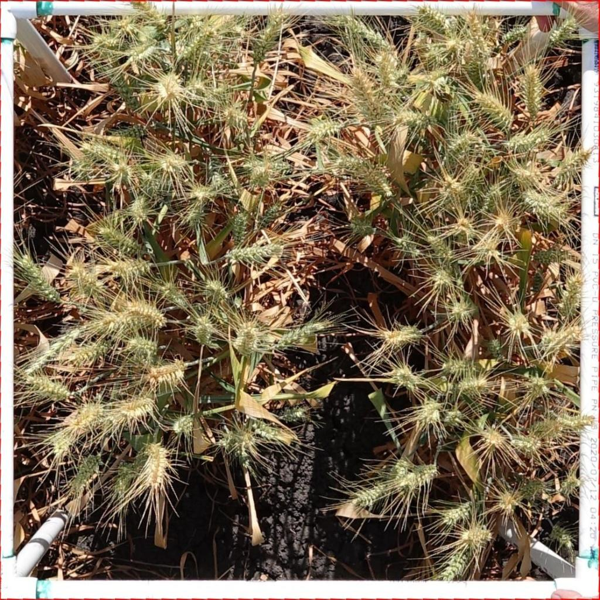

Image 512 x 512 593,758 bytes


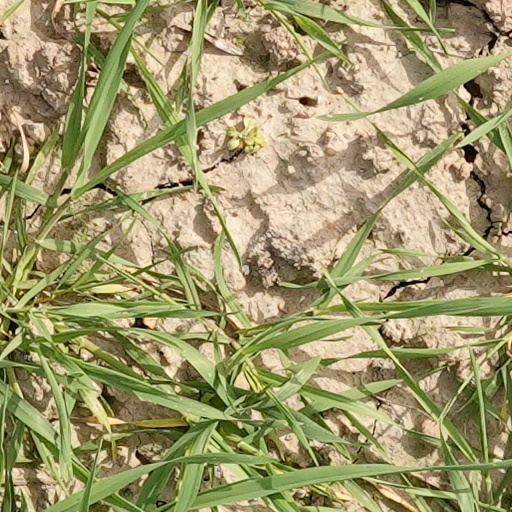

In [14]:
# Check image fetch and display

output = Path("images")
output.mkdir(exist_ok=True)

images = {
    "gwhd-00000000.jpg":
        "https://data.global-wheat.com/gwhd/images/00000000.jpg",
    "gwfss-00000000.png":
        "https://data.global-wheat.com/gwfss/images/00000000.png",   
}

for file, url in images.items():
    response = requests.get(url, timeout=5)
    response.raise_for_status()

    img = Image.open(BytesIO(response.content))
    img.load()

    dest = output / file
    dest.write_bytes(response.content)

    print(f"Image {img.width} x {img.height}", f"{len(response.content):,} bytes")

    preview = img.copy()
    preview.thumbnail((600, 600))
    display(preview)

## Local GPU versus API inference

Run this section independently of the connectivity cells above. It uses one image from
the local Parquet sample for both runs; the API receives a lossless PNG upload of the
same RGB pixels. The default comparison is **SegFormer-B4 locally versus SegFormer-B4
through the API**.

- Set `GLOBAL_WHEAT_API_KEY` before starting Jupyter, or enter your participant key
  in the hidden prompt. Never paste a key into notebook source.
- Keep `LOCAL_DEVICE = "cuda"` on Renku. For a local CPU smoke run, explicitly set
  it to `"cpu"`; there is no automatic fallback.
- For an API-only CPU session, set `RUN_LOCAL = False`. For local-only execution,
  set `RUN_API = False`. Disabled paths are not replaced with sample predictions.
- SegFormer returns one mask/box per **organ class**, not per individual plant.
  The sample's spikelet/peduncle annotations are different; this is not an accuracy benchmark.


In [ ]:
import getpass
import os
import time
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from PIL import Image
from IPython.display import display
from pycocotools import mask as coco_mask
import requests

API_BASE = os.environ.get("GLOBAL_WHEAT_API", "https://api.global-wheat.com").rstrip("/")
API_MODEL = "gwfss-segformer-b4"
API_PARAMS = {}  # SegFormer takes no prompt/size parameters.
HF_MODEL = "GlobalWheat/GWFSS_Segformer_b4"
HF_REVISION = "6349b1a281d7d305845cac8ad56d2ae0d0060794"
DATA_FILE = Path(os.environ.get("DATA_FILE", "examples/train-00000-of-00001.parquet"))
SAMPLE_ROW = 0
RUN_API = True
RUN_LOCAL = True
LOCAL_DEVICE = "cuda"

CLASS_COLORS = {"head": "#ffbe28", "stem": "#32aaf0", "leaf": "#46c864"}


### Select the image and define a shared renderer

The renderer decodes compressed COCO RLE with `pycocotools`, checks mask dimensions
and pixel areas, and draws the API's **XYWH** bounding boxes in original-image
coordinates. Empty predictions still display the original image. Box-only results
are also supported.


In [ ]:
sample_table = pq.read_table(DATA_FILE, columns=["image", "image_id", "width", "height"])
sample = sample_table.slice(SAMPLE_ROW, 1).to_pylist()[0]
comparison_image = Image.open(BytesIO(sample["image"]["bytes"])).convert("RGB")
assert comparison_image.size == (sample["width"], sample["height"])
png_buffer = BytesIO()
comparison_image.save(png_buffer, format="PNG")
upload_bytes = png_buffer.getvalue()
print(f"{sample['image_id']}: {comparison_image.width} × {comparison_image.height}; "
      f"{len(upload_bytes):,} upload bytes")


def decode_prediction(prediction, image):
    objects = []
    for obj in prediction["objects"]:
        mask = None
        if obj.get("rle") is not None:
            rle = obj["rle"]
            mask = coco_mask.decode({
                "size": rle["size"],
                "counts": rle["counts"].encode("ascii"),
            }).astype(bool)
            if mask.shape != (image.height, image.width):
                raise ValueError(f"Mask shape {mask.shape} does not match image dimensions")
            if obj.get("area") is not None and int(mask.sum()) != obj["area"]:
                raise ValueError(f"Decoded area does not match object {obj['idx']}")
        objects.append({**obj, "mask": mask})
    return objects


def draw_prediction(ax, image, objects, title, opacity=0.4):
    overlay = np.asarray(image).copy()
    colors = []
    for i, obj in enumerate(objects):
        color = CLASS_COLORS.get(obj.get("category"), plt.get_cmap("tab20")(i % 20))
        from matplotlib.colors import to_rgb
        rgb = np.array(to_rgb(color))
        colors.append(rgb)
        mask = obj.get("mask")
        if mask is not None:
            overlay[mask] = ((1 - opacity) * overlay[mask] + opacity * 255 * rgb).astype(np.uint8)
    ax.imshow(overlay)
    for obj, color in zip(objects, colors):
        x, y, width, height = obj["bbox"]
        ax.add_patch(Rectangle((x, y), width, height, fill=False, edgecolor=color, linewidth=1.5))
        label = f"{obj.get('category') or 'object'} #{obj['idx']}"
        if obj.get("score") is not None:
            label += f" {obj['score']:.2f}"
        ax.text(x, y, label, color="white", fontsize=8, va="bottom",
                bbox={"facecolor": color, "alpha": 0.8, "edgecolor": "none", "pad": 2})
    ax.set_xlim(-0.5, image.width - 0.5)
    ax.set_ylim(image.height - 0.5, -0.5)
    ax.set_title(f"{title}\n{len(objects)} returned regions")
    ax.axis("off")


### Run inference through the API

The participant key goes only to `API_BASE`, not to the image CDN or Hugging Face.
Redirects are not followed with the key attached. The upload endpoint is **not
cached** according to the API contract, so this requests inference rather than a
previous published-row result. `computed_by` reports the backend that answered.
HTTP errors are shown instead of substituting local or recorded predictions.

To try SAM through the same API and renderer, change the configuration to
`API_MODEL = "sam3.1-meta"` and `API_PARAMS = {"prompt": "wheat head"}`, then rerun
this section. Local inference remains SegFormer: that becomes a cross-model
comparison, not a comparison of two implementations of the same model.


In [ ]:
def predict_via_api(image_bytes):
    key = os.environ.get("GLOBAL_WHEAT_API_KEY", "").strip()
    if not key:
        key = getpass.getpass("Participant API key (not saved): ").strip()
    if not key:
        raise ValueError("An API key is required; set RUN_API = False for a local-only run.")
    start = time.perf_counter()
    response = requests.post(
        f"{API_BASE}/models/{API_MODEL}/predict/upload",
        headers={"X-API-Key": key},
        files={"file": ("sample.png", image_bytes, "image/png")},
        params=API_PARAMS,
        timeout=(10, 120),
        allow_redirects=False,
    )
    elapsed = time.perf_counter() - start
    if response.status_code != 200:
        try:
            error = response.json()["error"]
            detail = f"{error['code']}: {error['message']}"
        except (ValueError, KeyError, TypeError):
            detail = response.reason
        raise RuntimeError(f"API HTTP {response.status_code}: {detail}")
    prediction = response.json()
    if prediction["model"] != API_MODEL:
        raise ValueError(f"API returned unexpected model {prediction['model']}")
    return prediction, elapsed


api_prediction = api_objects = api_seconds = None
if RUN_API:
    api_prediction, api_seconds = predict_via_api(upload_bytes)
    api_objects = decode_prediction(api_prediction, comparison_image)
    display({
        "model": api_prediction["model"],
        "computed_by": api_prediction.get("computed_by"),
        "resolution_used": api_prediction.get("resolution_used"),
        "cached": api_prediction.get("cached", False),
        "request_seconds_including_network": round(api_seconds, 3),
        "returned_regions": len(api_objects),
        "warnings": api_prediction.get("warnings", []),
    })
else:
    print("API inference intentionally disabled.")


### Run the same SegFormer checkpoint locally

The processor uses the slow preprocessing path, matching the documented API
backend. Model loading is outside the inference timer. The first execution
downloads the public checkpoint; the model is reused when this cell is rerun
with the same model, revision, and device. No API token is needed for this path.


In [ ]:
local_objects = local_report = None
if RUN_LOCAL:
    import torch
    import torch.nn.functional as F
    from transformers import AutoImageProcessor, SegformerForSemanticSegmentation

    if LOCAL_DEVICE == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA unavailable. Use a GPU session, set LOCAL_DEVICE = 'cpu' "
                           "explicitly, or set RUN_LOCAL = False for API-only execution.")
    model_key = (HF_MODEL, HF_REVISION, LOCAL_DEVICE)
    if globals().get("_comparison_model_key") != model_key:
        local_processor = AutoImageProcessor.from_pretrained(
            HF_MODEL, revision=HF_REVISION, use_fast=False
        )
        local_model = SegformerForSemanticSegmentation.from_pretrained(
            HF_MODEL, revision=HF_REVISION
        ).to(LOCAL_DEVICE).eval()
        _comparison_model_key = model_key

    model_device = next(local_model.parameters()).device
    if model_device.type == "cuda":
        torch.cuda.synchronize(model_device)
    start = time.perf_counter()
    with torch.inference_mode():
        inputs = local_processor(images=comparison_image, return_tensors="pt").to(model_device)
        logits = local_model(**inputs).logits
        assert logits.device == model_device
        probabilities = F.interpolate(
            logits, size=(comparison_image.height, comparison_image.width),
            mode="bilinear", align_corners=False,
        ).softmax(dim=1)[0]
        class_map = probabilities.argmax(dim=0)
        winning_scores = probabilities.gather(0, class_map.unsqueeze(0))[0].cpu().numpy()
        class_map = class_map.cpu().numpy()
    if model_device.type == "cuda":
        torch.cuda.synchronize(model_device)
    local_seconds = time.perf_counter() - start

    local_objects = []
    for class_id, category in local_model.config.id2label.items():
        if category == "background":
            continue
        mask = class_map == class_id
        ys, xs = np.nonzero(mask)
        if not len(xs):
            continue
        local_objects.append({
            "idx": len(local_objects), "category": category, "mask": mask,
            "bbox": [int(xs.min()), int(ys.min()),
                     int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1)],
            "score": float(winning_scores[mask].mean()), "area": int(mask.sum()),
        })
    local_report = {
        "model": HF_MODEL, "revision": HF_REVISION, "device": str(model_device),
        "output_device": str(logits.device),
        "gpu": torch.cuda.get_device_name(model_device) if model_device.type == "cuda" else None,
        "torch": str(torch.__version__), "cuda_runtime": torch.version.cuda,
        "inference_seconds_excluding_load": round(local_seconds, 3),
    }
    display(local_report)
    del inputs, logits, probabilities
else:
    print("Local inference intentionally disabled.")


### Compare masks and bounding boxes

Gold = head, blue = stem, green = leaf for SegFormer. Other categories use
per-object colors (for example, SAM's individual wheat heads). Bounding boxes
are the model's returned regions, not ground truth.

The API timing includes upload, network, queueing, and server work; the local
timing covers preprocessing, model execution, and class-map postprocessing.
These single requests are **not a controlled speed benchmark**. Different
runtime versions, devices, or backend weights can also produce different masks.


In [ ]:
panels = []
if local_objects is not None:
    panels.append((f"Local SegFormer ({local_report['device']})", local_objects))
if api_objects is not None:
    panels.append((f"API: {api_prediction['model']}", api_objects))
if not panels:
    raise RuntimeError("Enable and run at least one inference path before rendering.")

fig, axes = plt.subplots(1, 1 + len(panels), figsize=(5 * (1 + len(panels)), 9), squeeze=False)
axes[0, 0].imshow(comparison_image)
axes[0, 0].set_title(f"Original: {sample['image_id']}")
axes[0, 0].axis("off")
for ax, (title, objects) in zip(axes[0, 1:], panels):
    draw_prediction(ax, comparison_image, objects, title)
fig.tight_layout()
plt.show()
plt.close(fig)

rows = []
for title, objects in panels:
    for obj in objects:
        rows.append({
            "source": title, "idx": obj["idx"], "category": obj.get("category"),
            "score": obj.get("score"), "area_pixels": obj.get("area"),
            "bbox_xywh": obj["bbox"],
        })
display(pd.DataFrame(rows, columns=["source", "idx", "category", "score", "area_pixels", "bbox_xywh"]))